# 04 — Feature Engineering & Panel Construction

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Build master analysis panel, define treatments, outcomes, confounders  
**Input:** `data/interim/` (from Notebook 02)  
**Output:** `data/processed/analysis_panel.csv`, `data/processed/treatment_matrix.csv`

---

In [1]:
import sys
import warnings
from pathlib import Path

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import (
    create_treatment_variables, create_outcome_variables,
    create_lagged_features, build_analysis_panel
)
from src.visualization import set_publication_style, COLORS

INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

set_publication_style()

In [2]:
# Load cleaned data
df_emissions = pd.read_csv(INTERIM_DIR / "emissions_cleaned.csv")
df_energy = pd.read_csv(INTERIM_DIR / "energy_cleaned.csv")
treatment_df = pd.read_csv(INTERIM_DIR / "wcpd_treatment_cleaned.csv")
df_covariates = pd.read_csv(INTERIM_DIR / "covariates_merged.csv")

print(f"Emissions: {df_emissions.shape}")
print(f"Energy: {df_energy.shape}")
print(f"WCPD treatment: {treatment_df.shape}")
print(f"Covariates: {df_covariates.shape}")


Emissions: (7630, 15)
Energy: (7696, 15)
WCPD treatment: (6834, 7)
Covariates: (7630, 41)


---
## 4.1 — Create Treatment Variables

In [3]:
print("=" * 60)
print("4.1 - Carbon-Pricing Treatment Variable (from WCPD)")
print("=" * 60)

# treatment_df was already built in Notebook 02 from the World Carbon
# Pricing Database (src.preprocessing.build_carbon_price_treatment) -
# no keyword matching here, just a summary of what was loaded.
treat_cols = [c for c in treatment_df.columns if c.startswith("treat_")]
print(f"Treatment columns: {treat_cols}")
print()
print("Treatment summary (latest year):")
latest = treatment_df[treatment_df["year"] == treatment_df["year"].max()]
for col in treat_cols:
    n_treated = latest[col].sum()
    n_total = len(latest)
    print(f"  {col}: {int(n_treated)}/{n_total} countries treated ({n_treated/n_total*100:.1f}%)")


4.1 - Carbon-Pricing Treatment Variable (from WCPD)
Treatment columns: ['treat_carbon_price']

Treatment summary (latest year):
  treat_carbon_price: 45/201 countries treated (22.4%)


---
## 4.2 — Create Outcome Variables

In [4]:
print("=" * 60)
print("4.2 — Creating Outcome Variables")
print("=" * 60)

df_outcomes = create_outcome_variables(df_covariates)

outcome_cols = ["log_co2", "co2_intensity", "co2_growth", "co2_per_capita"]
outcome_cols = [c for c in outcome_cols if c in df_outcomes.columns]
print(f"Outcome variables created: {outcome_cols}")
print(f"\n{df_outcomes[outcome_cols].describe().round(3)}")

4.2 — Creating Outcome Variables
Outcome variables created: ['log_co2', 'co2_intensity', 'co2_growth', 'co2_per_capita']

        log_co2  co2_intensity  co2_growth  co2_per_capita
count  7508.000       6845.000    7243.000        7442.000
mean      1.867          0.027       3.526           5.023
std       2.853          0.152      29.699           7.795
min      -6.908          0.000    -100.000           0.000
25%      -0.159          0.000      -2.175           0.714
50%       1.970          0.002       1.900           2.745
75%       3.988          0.009       6.806           6.833
max       9.416          2.708    1541.429         364.791


---
## 4.3 — Create Lagged Features

In [5]:
print("=" * 60)
print("4.3 — Creating Lagged Features")
print("=" * 60)

lag_vars = ["co2", "gdp_per_capita"]
lag_vars = [v for v in lag_vars if v in df_outcomes.columns]

df_lagged = create_lagged_features(df_outcomes, value_cols=lag_vars, lags=[1, 3, 5])

lag_cols = [c for c in df_lagged.columns if "_lag" in c]
print(f"Lagged features: {lag_cols}")

4.3 — Creating Lagged Features
Lagged features: ['co2_lag1', 'co2_lag3', 'co2_lag5', 'gdp_per_capita_lag1', 'gdp_per_capita_lag3', 'gdp_per_capita_lag5']


---
## 4.4 — Build Master Analysis Panel

In [6]:
print("=" * 60)
print("4.4 — Building Master Analysis Panel")
print("=" * 60)

panel = build_analysis_panel(
    emissions_df=df_lagged,
    energy_df=df_energy,
    treatment_df=treatment_df,
)

print("\n Final Analysis Panel:")
print(f"   Rows: {panel.shape[0]:,}")
print(f"   Columns: {panel.shape[1]}")
print(f"   Countries: {panel['iso3'].nunique()}")
print(f"   Years: {panel['year'].min()} – {panel['year'].max()}")

# Column categories
print(f"\n   Outcome cols: {[c for c in panel.columns if c.startswith('log_') or c.startswith('co2')]}")
print(f"   Treatment cols: {[c for c in panel.columns if c.startswith('treat_')]}")
print(f"   Lag cols: {[c for c in panel.columns if '_lag' in c]}")

4.4 — Building Master Analysis Panel

 Final Analysis Panel:
   Rows: 7,630
   Columns: 68
   Countries: 218
   Years: 1990 – 2024

   Outcome cols: ['co2', 'co2_per_capita', 'co2_per_gdp', 'co2_growth_prct', 'co2_growth_abs', 'co2_power', 'co2_transport', 'co2_industry', 'co2_agriculture', 'log_co2', 'log_co2_power', 'log_co2_transport', 'log_co2_industry', 'log_co2_agriculture', 'co2_intensity', 'co2_growth', 'co2_lag1', 'co2_lag3', 'co2_lag5']
   Treatment cols: ['treat_carbon_price']
   Lag cols: ['co2_lag1', 'co2_lag3', 'co2_lag5', 'gdp_per_capita_lag1', 'gdp_per_capita_lag3', 'gdp_per_capita_lag5']


---
## 4.5 — Propensity Score Diagnostics

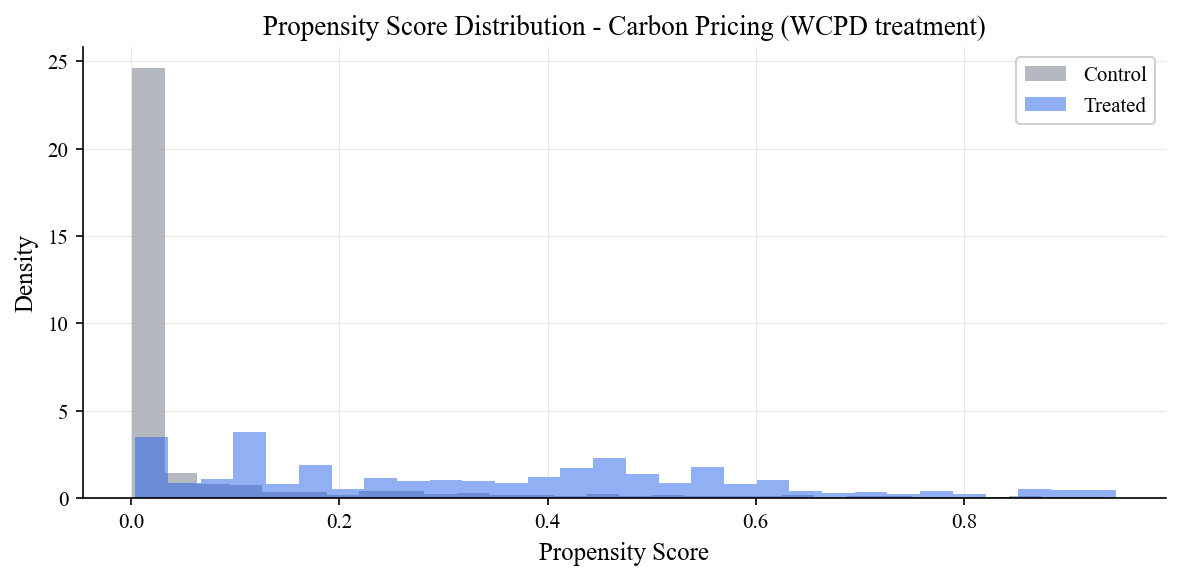

Propensity score range: [0.001, 0.946]
Overlap check: Sufficient


In [7]:
# Check overlap assumption: propensity score distribution

treat_col = "treat_carbon_price"
if treat_col in panel.columns:
    covar_cols = ["gdp_per_capita", "population", "urban_pct"]
    covar_cols = [c for c in covar_cols if c in panel.columns]

    ps_data = panel[[treat_col] + covar_cols].dropna()

    if len(ps_data) > 100 and ps_data[treat_col].nunique() > 1:
        X_ps = ps_data[covar_cols].values
        T_ps = ps_data[treat_col].values

        gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
        propensity = cross_val_predict(gb, X_ps, T_ps, cv=5, method="predict_proba")[:, 1]

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(propensity[T_ps == 0], bins=30, alpha=0.5, label="Control", color=COLORS["neutral"], density=True)
        ax.hist(propensity[T_ps == 1], bins=30, alpha=0.5, label="Treated", color=COLORS["primary"], density=True)
        ax.set_xlabel("Propensity Score")
        ax.set_ylabel("Density")
        ax.set_title("Propensity Score Distribution - Carbon Pricing (WCPD treatment)")
        ax.legend()
        plt.tight_layout()
        plt.show()

        overlap_min = propensity.min()
        overlap_max = propensity.max()
        print(f"Propensity score range: [{overlap_min:.3f}, {overlap_max:.3f}]")
        sufficient = overlap_min < 0.1 and overlap_max > 0.9
        print(f"Overlap check: {'Sufficient' if sufficient else 'Limited overlap'}")
    else:
        print("Insufficient data for propensity score diagnostics")
else:
    print(f"Treatment column '{treat_col}' not found")


---
## 4.6 — Export Analysis Panel

In [8]:
print("=" * 60)
print("4.6 - Exporting Analysis Panel")
print("=" * 60)

# Restrict to WCPD's actual documented coverage: (a) years <=2022, since
# WCPD has no record for ANY jurisdiction after 2022 (the left-merge +
# fillna(0) would otherwise incorrectly reset already-adopted countries
# to "untreated" for 2023-2024); and (b) jurisdictions WCPD actually
# covers (201 national jurisdictions). Without restriction (b), the
# generic OWID emissions backbone brings in 9 overseas territories/
# dependencies (Bermuda, Greenland, Faroe Islands, Aruba, Curacao, Sint
# Maarten, Turks and Caicos, New Caledonia, French Polynesia) that WCPD
# does not track at all -- these got silently coded as "never-treated"
# by the left-merge + fillna(0), which is not a real coverage fact, just
# an artifact of the merge. They are not sovereign jurisdictions and have
# no WCPD coverage decision behind their "0", so they do not belong in
# the never-treated comparison group.
n_before = len(panel)
wcpd_jurisdictions = set(treatment_df["iso3"].unique())
panel = panel[(panel["year"] <= 2022) & (panel["iso3"].isin(wcpd_jurisdictions))].copy()
print(f"Restricted to WCPD coverage (<=2022, WCPD jurisdictions only): {n_before:,} -> {len(panel):,} rows")
print(f"Countries: {panel['iso3'].nunique()}")

panel.to_csv(PROCESSED_DIR / "analysis_panel.csv", index=False)
print(f"  analysis_panel.csv ({panel.shape[0]:,} rows x {panel.shape[1]} cols)")

treatment_df.to_csv(PROCESSED_DIR / "treatment_matrix.csv", index=False)
print("  treatment_matrix.csv")

print()
print(f"Analysis-ready panel exported to: {PROCESSED_DIR}")
print("Proceed to Notebook 05: ATT(g,t) Estimation")


4.6 - Exporting Analysis Panel
Restricted to WCPD coverage (<=2022, WCPD jurisdictions only): 7,630 -> 6,534 rows
Countries: 198


  analysis_panel.csv (6,534 rows x 68 cols)
  treatment_matrix.csv

Analysis-ready panel exported to: F:\Nexus_Projects\causal-climate-policy\data\processed
Proceed to Notebook 05: ATT(g,t) Estimation
